# La data derrière la Blue Wall : analyses
*Étude indépendante, non affiliée à la Karmine Corp.*

Chaque section répond à la question d'une page du rapport.
- **RÉEL** : catalogue de la boutique, résultats sportifs, audience, streams de Kameto (voir `data/SOURCES.md`).
- **SIMULÉ** : ventes, clients, billetterie, test A/B. Ces données sont produites par `src/generate_sim.py` avec une graine fixe. **Ce ne sont pas des données de la KC.**
- **ESTIMATION** : les gains chiffrés, avec leurs hypothèses écrites noir sur blanc.

Les tables agrégées viennent des requêtes SQL (`sql/`, lancées par `src/run_sql.py`).

In [1]:
from pathlib import Path
import numpy as np, pandas as pd, matplotlib.pyplot as plt
from scipy import stats
import statsmodels.formula.api as smf
from statsmodels.stats.proportion import proportions_ztest, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
CLEAN, OUTD = ROOT / "data" / "clean", ROOT / "data" / "output"
BLEU, ROUGE, GRIS, NUIT = "#2F6BD6", "#C93636", "#A3A3A3", "#101E35"
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
                     "font.size": 10})
rng = np.random.default_rng(7)
FIN = pd.Timestamp("2026-11-08")
MOIS_PERIODE = 22.25            # 01/01/2025 -> 08/11/2026, pour annualiser
lire = lambda n: pd.read_csv(OUTD / f"{n}.csv")

produits = pd.read_csv(CLEAN / "sim_produits.csv", parse_dates=["date_lancement"])
commandes = pd.read_csv(CLEAN / "sim_commandes.csv", parse_dates=["date_commande"])
lignes = pd.read_csv(CLEAN / "sim_lignes.csv")
stock = pd.read_csv(CLEAN / "sim_stock.csv", parse_dates=["date_rupture"])
L = (lignes.merge(commandes[["order_id", "date_commande", "client_id"]], on="order_id")
           .merge(produits[["product_id", "nom", "famille", "collection", "date_lancement",
                            "prix_plein_ttc", "cout_unitaire_ht", "precommande"]], on="product_id"))
L["jour"] = (L.date_commande - L.date_lancement).dt.days
gains = []   # tableau final de la page 6
print(f"{len(commandes):,} commandes simulées, {L.montant_ht.sum()/1e6:.2f} M€ HT sur la période")

103,405 commandes simulées, 7.66 M€ HT sur la période


## Page 1 · Audience et sponsors (RÉEL, plus une ESTIMATION)
**Question :** combien vaut l'audience de la KC pour un partenaire ?

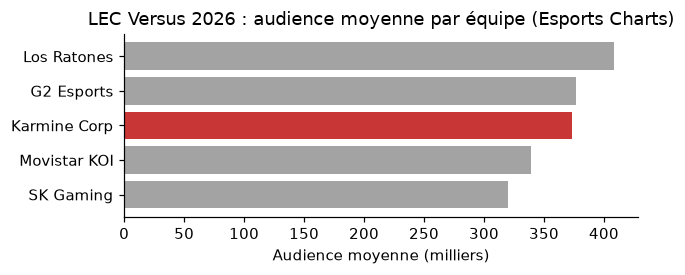

Part de l'audience du LEC Spring 2026 passée par les co-streams : 70%


In [2]:
aud = pd.read_csv(CLEAN / "audience_2026.csv")
eq = aud[aud.mesure.str.startswith("audience moyenne") & (aud.evenement == "LEC Versus 2026")].copy()
eq["equipe"] = eq.mesure.str.replace("audience moyenne ", "", regex=False)
eq = eq.sort_values("valeur")
fig, ax = plt.subplots(figsize=(6, 2.6))
ax.barh(eq.equipe, eq.valeur / 1000, color=[ROUGE if e == "Karmine Corp" else GRIS for e in eq.equipe])
ax.set_xlabel("Audience moyenne (milliers)"); ax.set_title("LEC Versus 2026 : audience moyenne par équipe (Esports Charts)")
plt.tight_layout(); plt.show()
spring = aud[aud.evenement == "LEC Spring 2026"].set_index("mesure").valeur
part_co = spring[spring.index.str.contains("co-streams")].iloc[0]
print(f"Part de l'audience du LEC Spring 2026 passée par les co-streams : {part_co:.0%}")

In [3]:
kam = pd.read_csv(CLEAN / "kameto_twitch.csv")
g = kam.groupby("match_kc_ce_jour").spectateurs_moyens.agg(["mean", "count"])
ratio = g.loc[1, "mean"] / g.loc[0, "mean"]
print(g.rename(index={0: "sans match KC", 1: "avec match KC"}).round(0))
print(f"Les jours de match de la KC, Kameto fait {ratio:.1f} fois plus de spectateurs moyens "
      f"(petit échantillon : {int(g['count'].sum())} streams, à présenter comme une indication).")

res = pd.read_csv(CLEAN / "kameto_twitch_resume_365j.csv").set_index("mesure").valeur
heures = res["heures regardées"]
# ESTIMATION : 1 heure regardée = 1 impression d'un logo partenaire à l'écran ; CPM de 5 à 10 €
valeur_bas, valeur_haut = heures * 5 / 1000, heures * 10 / 1000
print(f"Heures regardées chez Kameto sur 365 jours : {heures/1e6:.1f} M")
print(f"Valeur média d'un logo sur ce seul canal : {valeur_bas/1e3:,.0f} à {valeur_haut/1e3:,.0f} k€ par an (ESTIMATION)")

                     mean  count
match_kc_ce_jour                
sans match KC     28341.0      6
avec match KC     90901.0      3
Les jours de match de la KC, Kameto fait 3.2 fois plus de spectateurs moyens (petit échantillon : 9 streams, à présenter comme une indication).
Heures regardées chez Kameto sur 365 jours : 34.9 M
Valeur média d'un logo sur ce seul canal : 175 à 349 k€ par an (ESTIMATION)


In [4]:
# Gain : un rapport d'audience propre aide à revaloriser les contrats renouvelés.
SPONSORING_PUBLIE = 2_300_000        # Sheep Esports, 2024 (année 2023)
gains.append(dict(levier="Sponsors : rapport d'audience pour les renouvellements",
                  gain_bas=SPONSORING_PUBLIE * .03, gain_haut=SPONSORING_PUBLIE * .08,
                  hypothese="+3 % à +8 % sur ~2,3 M€ de sponsoring annuel (chiffre publié pour 2023)",
                  nature="chiffre d'affaires"))
print(gains[-1])

{'levier': "Sponsors : rapport d'audience pour les renouvellements", 'gain_bas': 69000.0, 'gain_haut': 184000.0, 'hypothese': '+3 % à +8 % sur ~2,3 M€ de sponsoring annuel (chiffre publié pour 2023)', 'nature': "chiffre d'affaires"}


## Page 2 · Boutique : stock, tailles et démarques (RÉEL, plus SIMULÉ)
**Question :** comment vendre plus au prix plein et solder moins ?

In [5]:
coll = lire("01_ventes_par_collection")
cols = ["collection", "ca_ht", "taux_marge", "part_unites_prix_plein", "part_j0_j3_sur_4_semaines",
        "taux_ecoulement", "valeur_stock_final_ht"]
coll[cols].head(12)

,collection,ca_ht,taux_marge,part_unites_prix_plein,part_j0_j3_sur_4_semaines,taux_ecoulement,valeur_stock_final_ht
0,Pro Kit 2026,1980258.0,0.631,0.787,0.523,0.892,91529.0
1,Pro Kit 2025,1445812.0,0.644,0.991,0.463,0.881,65475.0
2,Campus,657108.0,0.618,0.940,0.402,0.633,135420.0
3,Worlds 2026,617895.0,0.641,1.000,0.513,0.902,588.0
4,Collab Blue Lock,503258.0,0.618,0.834,0.450,0.563,146296.0
5,FW25,476264.0,0.596,0.863,0.399,0.580,144629.0
6,Eternal 2026,396576.0,0.645,0.949,0.462,0.859,21483.0
7,Cartes et TCG,275424.0,0.494,0.976,0.485,0.970,5150.0
8,Basket,251083.0,0.627,0.831,0.453,0.570,69689.0
9,Accessoires,221220.0,0.680,0.887,0.344,0.597,49918.0


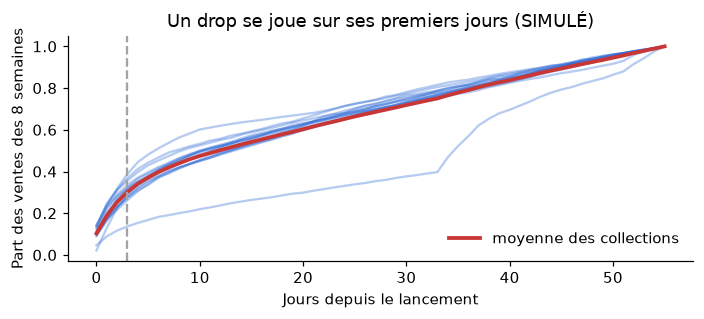

En moyenne, 30% des ventes des 8 premières semaines sont faites entre J0 et J3.


In [6]:
cb = lire("02_courbe_lancement")
fig, ax = plt.subplots(figsize=(6.5, 3))
for c, d in cb.groupby("collection"):
    ax.plot(d.jour, d.part_cumulee_8_semaines, color=BLEU, alpha=.35)
moy = cb.groupby("jour").part_cumulee_8_semaines.mean()
ax.plot(moy.index, moy.values, color=ROUGE, lw=2.5, label="moyenne des collections")
ax.axvline(3, color=GRIS, ls="--"); ax.set_xlabel("Jours depuis le lancement")
ax.set_ylabel("Part des ventes des 8 semaines"); ax.legend(frameon=False)
ax.set_title("Un drop se joue sur ses premiers jours (SIMULÉ)")
plt.tight_layout(); plt.show()
print(f"En moyenne, {moy.loc[3]:.0%} des ventes des 8 premières semaines sont faites entre J0 et J3.")

### Prévoir la demande d'un drop à partir de ses 4 premiers jours
Modèle log-log au niveau du produit : `log(ventes J0-J55) = a + b·log(ventes J0-J3) + groupe` (maillot, textile ou autre).
- Entraînement sur les produits lancés en **2025**, test sur ceux lancés en **2026** (données mises de côté).
- Référence naïve : ventes J0-J3 multipliées par le ratio médian observé en 2025.
- Les produits tombés en rupture avant J55 sont exclus : leurs ventes ne reflètent plus la demande.

In [7]:
elig = produits[(produits.date_lancement >= "2025-01-01") & (produits.date_lancement + pd.Timedelta(days=55) <= FIN)
                & (produits.famille != "service") & (produits.precommande == 0)].copy()
rupt = (stock.merge(produits[["product_id", "date_lancement"]], on="product_id")
             .assign(r=lambda d: (d.date_rupture - d.date_lancement).dt.days < 55)
             .groupby("product_id").r.mean())
elig = elig[elig.product_id.map(rupt).fillna(0) < .5]
v = L[L.product_id.isin(elig.product_id)]
agg = pd.DataFrame({"j0_3": v[v.jour.between(0, 3)].groupby("product_id").quantite.sum(),
                    "j0_55": v[v.jour.between(0, 55)].groupby("product_id").quantite.sum()}).fillna(0)
d = elig.set_index("product_id")[["nom", "famille", "date_lancement"]].join(agg).dropna()
d = d[(d.j0_3 > 0) & (d.j0_55 > 0)]
d["test"] = d.date_lancement >= "2026-01-01"
d["groupe"] = np.where(d.famille.isin(["maillot", "textile"]), d.famille, "autre")   # cartes, accessoires...
train, test = d[~d.test], d[d.test]
m = smf.ols("np.log(j0_55) ~ np.log(j0_3) + C(groupe)", data=train).fit()
k = (train.j0_55 / train.j0_3).median()
k_groupe = (train.j0_55 / train.j0_3).groupby(train.groupe).median()
test = test.assign(prev_regression=np.exp(m.predict(test)) * np.exp(m.mse_resid / 2),
                   prev_ratio=test.j0_3 * k,
                   prev_ratio_groupe=test.j0_3 * test.groupe.map(k_groupe))
wape = lambda y, p: np.abs(y - p).sum() / y.sum()
scores = pd.Series({"Régression log-log": wape(test.j0_55, test.prev_regression),
                    f"Ratio unique (x{k:.1f})": wape(test.j0_55, test.prev_ratio),
                    "Ratio par groupe": wape(test.j0_55, test.prev_ratio_groupe)}).sort_values()
print(f"{len(train)} produits d'entraînement (2025), {len(test)} de test (2026)")
print("Ratios par groupe (ventes J0-J55 / ventes J0-J3) :", k_groupe.round(2).to_dict())
print("Erreur (WAPE) sur les produits 2026, mis de côté :"); print(scores.map("{:.1%}".format).to_string())
print(f"Méthode retenue : {scores.index[0]} (la plus simple qui valide le mieux)")
test[["nom", "groupe", "j0_3", "j0_55", "prev_regression", "prev_ratio", "prev_ratio_groupe"]].round(0).to_csv(OUTD / "nb_prevision_drops.csv")
scores.rename("wape").to_csv(OUTD / "nb_prevision_scores.csv")

56 produits d'entraînement (2025), 22 de test (2026)
Ratios par groupe (ventes J0-J55 / ventes J0-J3) : {'autre': 5.36, 'maillot': 2.87, 'textile': 3.32}
Erreur (WAPE) sur les produits 2026, mis de côté :
Ratio unique (x3.5)    22.0%
Régression log-log     28.1%
Ratio par groupe       39.2%
Méthode retenue : Ratio unique (x3.5) (la plus simple qui valide le mieux)


### Courbe de tailles : ce qu'on commande face à ce qu'on vend
Les ruptures RÉELLES par taille (relevé de la boutique) et la simulation racontent la même chose : on manque de XXL et de 3XL, et il reste des XS.

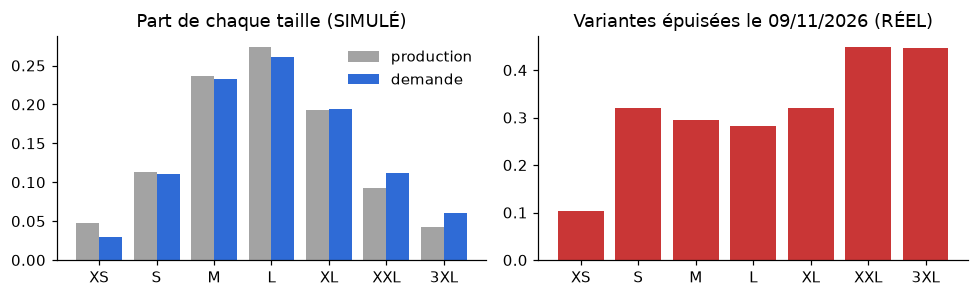

Ventes récupérées avec la bonne courbe de tailles : 12,689 pièces sur la période
Marge moyenne d'une pièce vendue au prix plein : 36.7 € HT


{'levier': 'Stock : courbe de tailles calée sur la demande', 'gain_bas': np.float64(125456.67989157968), 'gain_haut': np.float64(250913.35978315937), 'hypothese': '50 à 100 % des ventes perdues par taille récupérées, à la marge du prix plein', 'nature': 'marge'}


In [8]:
t = lire("03_tailles").set_index("taille").loc[["XS", "S", "M", "L", "XL", "XXL", "3XL"]]
fig, axes = plt.subplots(1, 2, figsize=(9, 2.8))
x = np.arange(len(t))
axes[0].bar(x - .2, t.part_production, .4, color=GRIS, label="production")
axes[0].bar(x + .2, t.part_demande, .4, color=BLEU, label="demande")
axes[0].set_xticks(x, t.index); axes[0].legend(frameon=False); axes[0].set_title("Part de chaque taille (SIMULÉ)")
axes[1].bar(x, t.part_variantes_epuisees_reel, color=ROUGE)
axes[1].set_xticks(x, t.index); axes[1].set_title("Variantes épuisées le 09/11/2026 (RÉEL)")
plt.tight_layout(); plt.show()

# Même production totale, répartie selon la demande : combien de ventes en plus, combien de stock en moins ?
t["demande"] = t.vendues + t.ventes_perdues_verite
t["prod_ideale"] = t.production.sum() * t.part_demande / t.part_demande.sum()
t["vendues_ideal"] = np.minimum(t.demande, t.prod_ideale)
ventes_en_plus = t.vendues_ideal.sum() - t.vendues.sum()
pp = L[(L.famille.isin(["maillot", "textile"])) & (L.remise_pct == 0)]
marge_piece = pp.marge_ht.sum() / pp.quantite.sum()
an = 12 / MOIS_PERIODE
print(f"Ventes récupérées avec la bonne courbe de tailles : {ventes_en_plus:,.0f} pièces sur la période")
print(f"Marge moyenne d'une pièce vendue au prix plein : {marge_piece:.1f} € HT")
gains.append(dict(levier="Stock : courbe de tailles calée sur la demande",
                  gain_bas=.5 * ventes_en_plus * marge_piece * an, gain_haut=ventes_en_plus * marge_piece * an,
                  hypothese="50 à 100 % des ventes perdues par taille récupérées, à la marge du prix plein",
                  nature="marge"))
t[["production", "vendues", "ventes_perdues_verite", "part_production", "part_demande", "prod_ideale",
   "part_variantes_epuisees_reel"]].round(3).to_csv(OUTD / "nb_tailles.csv")
print(gains[-1])

### Ce que coûtent les remises

In [9]:
rm = lire("04_remises_marge")
tab = rm.groupby("tranche_remise")[["unites", "ca_ht", "marge_ht"]].sum()
tab["taux_marge"] = tab.marge_ht / tab.ca_ht
tab["marge_par_piece"] = tab.marge_ht / tab.unites
print(tab.round(2))

# Production évitable = pièces soldées à 50 % ou plus + stock restant au 08/11/2026
liquid = L[(L.remise_pct >= .5) & (L.famille.isin(["maillot", "textile"]))]
stk = stock.merge(produits[["product_id", "famille", "cout_unitaire_ht", "prix_plein_ttc"]], on="product_id")
stk = stk[stk.famille.isin(["maillot", "textile"]) & (stk.fabrique_a_la_commande == 0)]
surplus_unites = liquid.quantite.sum() + stk.stock_final.sum()
cout_moyen = (stk.stock_initial * stk.cout_unitaire_ht).sum() / stk.stock_initial.sum()
# Une pièce non produite économise son coût ; si elle aurait été soldée, on perd son prix de solde :
# économie nette = coût - prix de solde HT. Une pièce restée en stock fait perdre tout son coût.
prix_solde_ht = liquid.montant_ht.sum() / liquid.quantite.sum()
print(f"Surplus sur la période : {surplus_unites:,.0f} pièces (soldées à -50 % ou plus, ou encore en stock)")
print(f"Coût moyen d'une pièce : {cout_moyen:.1f} € HT ; prix moyen en solde profonde : {prix_solde_ht:.1f} € HT")
n_liq, n_stk = liquid.quantite.sum(), stk.stock_final.sum()
gain_par_piece_evitee = (n_liq * (cout_moyen - prix_solde_ht).clip(min=0) + n_stk * cout_moyen) / surplus_unites
gains.append(dict(levier="Stock : produire au plus juste chaque drop (moins de soldes et d'invendus)",
                  gain_bas=.10 * surplus_unites * gain_par_piece_evitee * an,
                  gain_haut=.25 * surplus_unites * gain_par_piece_evitee * an,
                  hypothese="10 à 25 % du surplus évité grâce à la prévision J0-J3 ; gain = coût non engagé net du prix de solde",
                  nature="marge"))
print(gains[-1])

                    unites      ca_ht   marge_ht  taux_marge  marge_par_piece
tranche_remise                                                               
1. Prix plein     146595.0  6912633.0  4389710.0        0.64            29.94
2. Moins de 30 %    7325.0   398447.0   233905.0        0.59            31.93
3. 30 à 49 %        8130.0   191480.0    76071.0        0.40             9.36
4. 50 à 69 %        1021.0    14121.0      681.0        0.05             0.67
5. 70 % et plus      157.0      898.0     -466.0       -0.52            -2.97
Surplus sur la période : 39,736 pièces (soldées à -50 % ou plus, ou encore en stock)
Coût moyen d'une pièce : 20.5 € HT ; prix moyen en solde profonde : 19.8 € HT
{'levier': "Stock : produire au plus juste chaque drop (moins de soldes et d'invendus)", 'gain_bas': np.float64(43400.095823496), 'gain_haut': np.float64(108500.23955873998), 'hypothese': '10 à 25 % du surplus évité grâce à la prévision J0-J3 ; gain = coût non engagé net du prix de solde', 

## Page 3 · Fans : RFM, réachat et LTV (SIMULÉ)
**Question :** qui rachète, et quand faut-il relancer ?

In [10]:
rfm = lire("05_rfm")
seg = rfm.groupby("segment").agg(clients=("client_id", "count"), ca_ht=("montant_ht", "sum"),
                                 frequence=("frequence", "mean"), recence=("recence_jours", "median"))
seg["part_clients"] = seg.clients / seg.clients.sum(); seg["part_ca"] = seg.ca_ht / seg.ca_ht.sum()
seg.round(3)

,clients,ca_ht,frequence,recence,part_clients,part_ca
segment,,,,,,
1. Noyau dur,2290,1151641.83,6.951,45.0,0.034,0.150
2. Fidèles,2912,766665.86,3.516,175.0,0.043,0.100
3. Fidèles à réactiver,1510,443729.57,3.591,418.0,0.022,0.058
4. En train de s'attacher,6659,947482.48,2.000,131.0,0.098,0.124
5. Nouveaux,18782,1202967.54,1.000,62.0,0.276,0.157
6. À relancer,10201,771945.13,1.000,275.0,0.150,0.101
7. Endormis,25718,2375541.20,1.148,478.0,0.378,0.310


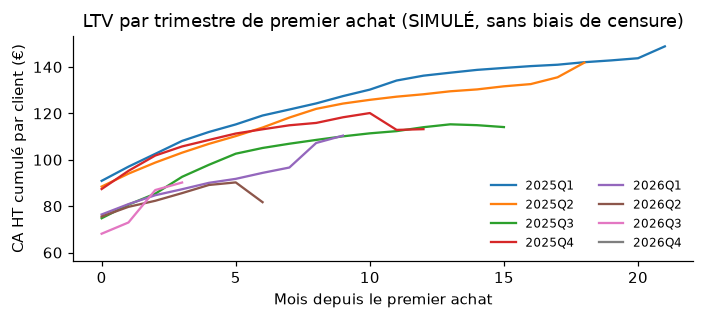

LTV à 12 mois (moyenne pondérée des cohortes observées 12 mois) : 124 € HT


,trimestre_premier_achat,nouveaux_clients,reachat_90j,reachat_180j,part_multi_drops
0,2025-T1,6663,0.173,0.241,0.226
1,2025-T2,6348,0.166,0.234,0.387
2,2025-T3,7928,0.185,0.267,0.460
3,2025-T4,10192,0.187,0.242,0.385
4,2026-T1,10132,0.140,0.193,0.401
5,2026-T2,7616,0.126,0.205,0.414
6,2026-T3,8974,0.173,NaN,0.356
7,2026-T4,6259,NaN,NaN,0.309


In [11]:
ltv = lire("06_ltv_cohortes")
ltv["cohorte"] = pd.to_datetime(ltv.cohorte)
ltv["trimestre"] = ltv.cohorte.dt.to_period("Q").astype(str)
fig, ax = plt.subplots(figsize=(6.5, 3))
for q, dq in ltv.groupby("trimestre"):
    w = dq.groupby("mois_depuis_premier_achat").apply(lambda x: np.average(x.ca_cumule_par_client_ht, weights=x.clients))
    ax.plot(w.index, w.values, label=q)
ax.set_xlabel("Mois depuis le premier achat"); ax.set_ylabel("CA HT cumulé par client (€)")
ax.legend(frameon=False, ncol=2, fontsize=8); ax.set_title("LTV par trimestre de premier achat (SIMULÉ, sans biais de censure)")
plt.tight_layout(); plt.show()
l12 = ltv[ltv.mois_depuis_premier_achat == 12]
print(f"LTV à 12 mois (moyenne pondérée des cohortes observées 12 mois) : {np.average(l12.ca_cumule_par_client_ht, weights=l12.clients):.0f} € HT")
rea = lire("07_reachat"); rea

In [12]:
# Gain CRM : relancer les segments « À relancer » et « Fidèles à réactiver » avant chaque drop
cibles = seg.loc[["6. À relancer", "3. Fidèles à réactiver"], "clients"].sum()
panier_ht = commandes.montant_net_ht.mean()
taux_marge = L.marge_ht.sum() / L.montant_ht.sum()
N_CAMPAGNES = 4                                   # un envoi ciblé par grand drop
for nom, up in [("bas", .01), ("haut", .03)]:
    print(f"{nom} : +{up:.0%} de réachat incrémental x {cibles:,} clients x {panier_ht:.0f} € x {N_CAMPAGNES} campagnes")
gains.append(dict(levier="CRM : relancer les bons segments avant un drop et après un match",
                  gain_bas=cibles * .01 * panier_ht * taux_marge * N_CAMPAGNES,
                  gain_haut=cibles * .03 * panier_ht * taux_marge * N_CAMPAGNES,
                  hypothese=f"+1 à +3 points de réachat incrémental sur {cibles:,} clients ciblés, 4 campagnes par an, marge {taux_marge:.0%}",
                  nature="marge"))
print(gains[-1])

bas : +1% de réachat incrémental x 11,711 clients x 74 € x 4 campagnes
haut : +3% de réachat incrémental x 11,711 clients x 74 € x 4 campagnes
{'levier': 'CRM : relancer les bons segments avant un drop et après un match', 'gain_bas': np.float64(21807.2991870388), 'gain_haut': np.float64(65421.89756111639), 'hypothese': '+1 à +3 points de réachat incrémental sur 11,711 clients ciblés, 4 campagnes par an, marge 63%', 'nature': 'marge'}


## Page 4 · Événements et Arènes (RÉEL pour les dates et capacités, SIMULÉ pour les ventes)
**Question :** comment remplir plus de dates, et mieux ?

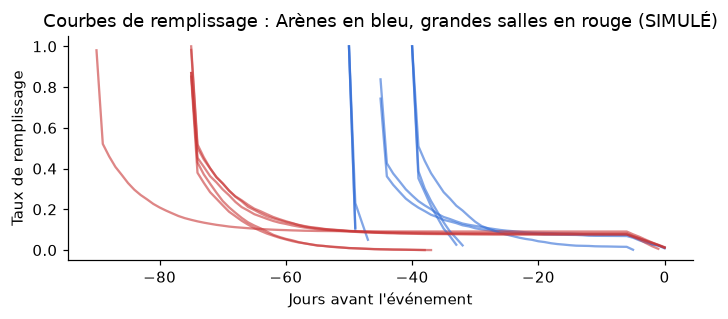

In [13]:
ev = lire("09_billetterie"); ev["date_evenement"] = pd.to_datetime(ev.date_evenement)
billets = pd.read_csv(CLEAN / "sim_billets.csv")
evs = pd.read_csv(CLEAN / "sim_evenements.csv", parse_dates=["date_evenement"])
cum = (billets.groupby(["event_id", "jours_avant_evenement"]).billets.sum().groupby(level=0).cumsum()
              .reset_index().merge(evs[["event_id", "capacite", "lieu"]], on="event_id"))
fig, ax = plt.subplots(figsize=(6.5, 3))
for e, de in cum.groupby("event_id"):
    de = de.sort_values("jours_avant_evenement", ascending=False)
    ax.plot(-de.jours_avant_evenement, de.billets / de.capacite, color=BLEU if "Arènes" in de.lieu.iat[0] else ROUGE, alpha=.6)
ax.set_xlabel("Jours avant l'événement"); ax.set_ylabel("Taux de remplissage")
ax.set_title("Courbes de remplissage : Arènes en bleu, grandes salles en rouge (SIMULÉ)")
plt.tight_layout(); plt.show()

### Prévoir le remplissage final à partir des 48 premières heures
Modèle simple : `remplissage final = min(1 ; k × part vendue en 48 h)`. `k` est estimé sur les événements 2024-2025 qui n'ont **pas** été complets (pour eux, la demande totale est connue). Le modèle est testé sur les événements 2026.

In [14]:
ok = ev[ev.reporte_rembourse == 0]
train = ok[(ok.date_evenement < "2026-01-01") & (ok.taux_remplissage < 1)]
k = (train.taux_remplissage / train.part_capacite_vendue_48h).median()
test = ok[ok.date_evenement >= "2026-01-01"].copy()
test["prevision"] = np.minimum(1, k * test.part_capacite_vendue_48h)
test["erreur_points"] = (test.prevision - test.taux_remplissage) * 100
print(f"k = {k:.2f} (estimé sur {len(train)} événements non complets)")
print(test[["nom", "part_capacite_vendue_48h", "taux_remplissage", "prevision", "erreur_points"]].round(3).to_string(index=False))
nc = test[test.taux_remplissage < 1]
print(f"Erreur absolue moyenne sur les {len(nc)} événements 2026 non complets : {nc.erreur_points.abs().mean():.1f} points "
      f"(les événements complets sont trivialement bien prévus)")
test.to_csv(OUTD / "nb_billetterie_prevision.csv", index=False)

k = 1.81 (estimé sur 3 événements non complets)
                     nom  part_capacite_vendue_48h  taux_remplissage  prevision  erreur_points
LEC Roadtrip Spring (J1)                     1.000             1.000      1.000          0.000
LEC Roadtrip Spring (J2)                     1.000             1.000      1.000          0.000
LEC Roadtrip Spring (J3)                     1.000             1.000      1.000          0.000
LEC Roadtrip Summer (J1)                     0.460             0.869      0.834         -3.463
LEC Roadtrip Summer (J2)                     0.545             1.000      0.989         -1.145
LEC Roadtrip Summer (J3)                     0.538             0.982      0.976         -0.615
Erreur absolue moyenne sur les 2 événements 2026 non complets : 2.0 points (les événements complets sont trivialement bien prévus)


In [15]:
# Demande non servie : les listes d'attente des événements complets
complets = ok[ok.taux_remplissage >= 1]
prix_moyen = (billets.ca_ttc.sum() / billets.billets.sum())
print(f"{len(complets)} événements complets ; liste d'attente moyenne : {complets.liste_attente.mean():.0f} personnes")
ca_date = 3000 * billets.merge(evs[["event_id", "lieu"]]).query("lieu == 'Les Arènes, Évry'").pipe(lambda b: b.ca_ttc.sum() / b.billets.sum())
print(f"Une date de plus aux Arènes complète : ~{ca_date/1e3:.0f} k€ TTC de billetterie (SIMULÉ)")
print("Repère publié : ~1,5 M€/an pour ~20 événements en pleine exploitation (Sheep Esports, 2024), soit ~75 k€ par événement.")
gains.append(dict(levier="Billetterie : chiffrer la demande non servie pour obtenir plus de dates",
                  gain_bas=1 * ca_date / 1.055, gain_haut=3 * ca_date / 1.055,
                  hypothese="1 à 3 dates de plus par an aux Arènes (3 000 places), au prix moyen simulé, TVA billetterie 5,5 % ; dépend du calendrier Riot",
                  nature="chiffre d'affaires HT"))
print(gains[-1])

9 événements complets ; liste d'attente moyenne : 581 personnes
Une date de plus aux Arènes complète : ~80 k€ TTC de billetterie (SIMULÉ)
Repère publié : ~1,5 M€/an pour ~20 événements en pleine exploitation (Sheep Esports, 2024), soit ~75 k€ par événement.
{'levier': 'Billetterie : chiffrer la demande non servie pour obtenir plus de dates', 'gain_bas': np.float64(76194.95781027617), 'gain_haut': np.float64(228584.8734308285), 'hypothese': '1 à 3 dates de plus par an aux Arènes (3 000 places), au prix moyen simulé, TVA billetterie 5,5 % ; dépend du calendrier Riot', 'nature': "chiffre d'affaires HT"}


## Page 5 · Les résultats font-ils vendre ? (résultats RÉELS, ventes SIMULÉES)
**1. Vue descriptive.** Pour chaque moment sportif, le CA du jour est rapporté à la médiane des jours J-24 à J-4 (hors promotions). Attention : les matchs de playoffs se suivent à quelques jours d'écart, donc les effets se chevauchent.

**2. Mesure.** On fait une régression sur les ventes jour par jour :
- `log(CA du jour)` ~ jour de la semaine + mois (qui absorbe les soldes de mars-avril 2026) + Black Friday + lancements + un indicateur par type de moment (fenêtre J0-J3) ;
- comme chaque type de moment est une variable à part, les chevauchements sont démêlés ;
- les erreurs standard sont robustes à l'autocorrélation (Newey-West, 7 jours).

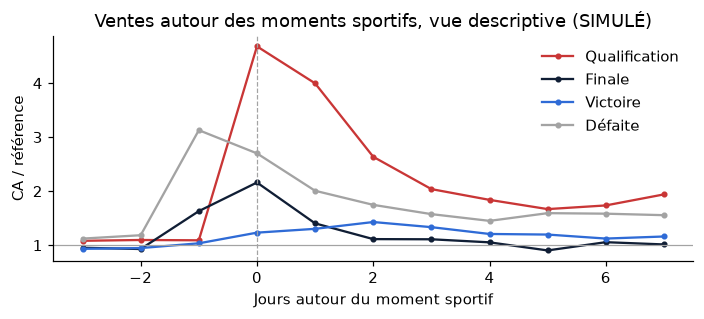

In [16]:
es = lire("08_effet_resultats")
prof = es.groupby(["type_moment", "jour_relatif"]).indice_ca.mean().unstack(0)
fig, ax = plt.subplots(figsize=(6.5, 3))
for c, col in zip(["Qualification", "Finale", "Victoire", "Défaite"], [ROUGE, NUIT, BLEU, GRIS]):
    if c in prof:
        ax.plot(prof.index, prof[c], marker="o", ms=3, color=col, label=c)
ax.axhline(1, color=GRIS, lw=.8); ax.axvline(0, color=GRIS, ls="--", lw=.8)
ax.set_xlabel("Jours autour du moment sportif"); ax.set_ylabel("CA / référence")
ax.legend(frameon=False); ax.set_title("Ventes autour des moments sportifs, vue descriptive (SIMULÉ)")
plt.tight_layout(); plt.show()
prof.round(3).to_csv(OUTD / "nb_profil_moments.csv")

In [17]:
jours = pd.date_range("2025-01-01", FIN)
df = pd.DataFrame(index=jours)
df["ca"] = L.groupby("date_commande").montant_ht.sum().reindex(jours, fill_value=0)
df["log_ca"] = np.log(df.ca + 1)
cal = lire("00_calendrier"); cal.index = pd.to_datetime(cal.date)
df["black_friday"], df["soldes"] = cal.black_friday, cal.soldes
df["dow"], df["mois"] = df.index.day_of_week, df.index.to_period("M").astype(str)
lanc = produits[produits.famille != "service"].groupby("collection").date_lancement.min()
lanc = lanc[lanc >= "2025-01-01"]
fenetre = lambda dates, a, b: pd.Series([any(a <= (d - x).days <= b for x in dates) for d in jours], index=jours).astype(int)
df["lancement_j0_3"], df["lancement_j4_10"] = fenetre(lanc, 0, 3), fenetre(lanc, 4, 10)
res = pd.read_csv(CLEAN / "kc_resultats_lol.csv", parse_dates=["date"])
res = res[~res.phase.str.startswith("Fin de saison")]
res["type"] = np.select([res.enjeu.fillna("").str.startswith("Qualifiée"), res.phase.eq("Finale"), res.resultat.eq("V")],
                        ["qualification", "finale", "victoire"], "defaite")
for typ, dt in res.groupby("type"):
    df[typ] = fenetre(dt.date, 0, 3)
reg = smf.ols("log_ca ~ C(dow) + C(mois) + black_friday + lancement_j0_3 + lancement_j4_10"
              " + qualification + finale + victoire + defaite", data=df).fit(cov_type="HAC", cov_kwds={"maxlags": 7})
noms = {"qualification": "Qualification", "finale": "Finale", "victoire": "Victoire", "defaite": "Défaite",
        "lancement_j0_3": "Lancement d'une collection (J0-J3)"}
ci = reg.conf_int()
effet = pd.DataFrame({"moment": [noms[k] for k in noms],
                      "nb_moments": [int(res.type.eq(k).sum()) if k in res.type.values else len(lanc) for k in noms],
                      "hausse_ca_j0_j3": [np.exp(reg.params[k]) - 1 for k in noms],
                      "ic95_bas": [np.exp(ci.loc[k, 0]) - 1 for k in noms],
                      "ic95_haut": [np.exp(ci.loc[k, 1]) - 1 for k in noms],
                      "p_value": [reg.pvalues[k] for k in noms]})
effet.round(3).to_csv(OUTD / "nb_effet_resultats.csv", index=False)
print(f"R² de la régression : {reg.rsquared:.2f} sur {len(df)} jours")
effet.round(3)

R² de la régression : 0.57 sur 677 jours


,moment,nb_moments,hausse_ca_j0_j3,ic95_bas,ic95_haut,p_value
0,Qualification,7,0.467,0.172,0.837,0.001
1,Finale,5,0.291,0.067,0.562,0.009
2,Victoire,12,0.127,-0.031,0.310,0.121
3,Défaite,12,-0.003,-0.157,0.179,0.971
4,Lancement d'une collection (J0-J3),14,1.822,0.984,3.014,0.000


### Test A/B (fictif) : guide des tailles sur la page du maillot

In [18]:
ab = pd.read_csv(CLEAN / "sim_ab_test.csv")
s = ab.groupby("variante").agg(n=("session_id", "count"), conv=("a_converti", "sum"), ca=("ca_ttc", "sum"))
z, p = proportions_ztest(s.conv.values[::-1], s.n.values[::-1])        # B contre A
cr = s.conv / s.n
lift = cr["B"] / cr["A"] - 1
# taille d'échantillon nécessaire pour détecter +10 % relatif à partir du taux de A
es_h = proportion_effectsize(cr["A"] * 1.10, cr["A"])
n_req = NormalIndPower().solve_power(effect_size=es_h, alpha=.05, power=.8, alternative="two-sided")
# bootstrap du CA par session
a = ab.loc[ab.variante == "A", "ca_ttc"].values; b = ab.loc[ab.variante == "B", "ca_ttc"].values
bd = np.array([rng.choice(b, len(b)).mean() - rng.choice(a, len(a)).mean() for _ in range(2000)])
print(f"Conversion A {cr['A']:.2%} | B {cr['B']:.2%} | hausse relative {lift:+.1%} | p = {p:.4f}")
print(f"Sessions nécessaires pour détecter +10 % (alpha 5 %, puissance 80 %) : {n_req:,.0f} par variante ; observées : {s.n.min():,}")
sem = n_req / (s.n.mean() / 4)
print(f"Le test est significatif, mais il était sous-dimensionné : il aurait fallu environ {sem:.1f} semaines au lieu de 4. "
      "La taille d'échantillon se fixe AVANT de lancer le test.")
print(f"CA par session : +{bd.mean():.2f} € TTC (IC 95 % : {np.percentile(bd, 2.5):.2f} à {np.percentile(bd, 97.5):.2f})")
pd.DataFrame([dict(conv_A=cr["A"], conv_B=cr["B"], hausse_relative=lift, p_value=p, n_requis_par_variante=n_req,
                   n_observe_par_variante=s.n.min(), gain_ca_session=bd.mean(),
                   ic_bas=np.percentile(bd, 2.5), ic_haut=np.percentile(bd, 97.5))]).to_csv(OUTD / "nb_ab_test.csv", index=False)

Conversion A 2.98% | B 3.40% | hausse relative +13.8% | p = 0.0033
Sessions nécessaires pour détecter +10 % (alpha 5 %, puissance 80 %) : 53,471 par variante ; observées : 31,197
Le test est significatif, mais il était sous-dimensionné : il aurait fallu environ 6.8 semaines au lieu de 4. La taille d'échantillon se fixe AVANT de lancer le test.
CA par session : +0.38 € TTC (IC 95 % : 0.11 à 0.67)


## Page 6 · Ce que rapporterait un data analyst (ESTIMATION)
Chaque ligne reprend un calcul ci-dessus, avec son hypothèse. Les montants sont annuels.

In [19]:
g = pd.DataFrame(gains)
g["gain_bas"] = g.gain_bas.round(-3); g["gain_haut"] = g.gain_haut.round(-3)
g.to_csv(OUTD / "gains_estimes.csv", index=False)
print(g[["levier", "gain_bas", "gain_haut", "nature"]].to_string(index=False))
print(f"\nTOTAL : {g.gain_bas.sum()/1e3:,.0f} k€ à {g.gain_haut.sum()/1e3:,.0f} k€ par an")
print("Repère : un data analyst junior à Paris coûte environ 55 à 65 k€ par an, charges comprises (hypothèse).")

                                                                    levier  gain_bas  gain_haut                nature
                    Sponsors : rapport d'audience pour les renouvellements   69000.0   184000.0    chiffre d'affaires
                            Stock : courbe de tailles calée sur la demande  125000.0   251000.0                 marge
Stock : produire au plus juste chaque drop (moins de soldes et d'invendus)   43000.0   109000.0                 marge
          CRM : relancer les bons segments avant un drop et après un match   22000.0    65000.0                 marge
   Billetterie : chiffrer la demande non servie pour obtenir plus de dates   76000.0   229000.0 chiffre d'affaires HT

TOTAL : 335 k€ à 838 k€ par an
Repère : un data analyst junior à Paris coûte environ 55 à 65 k€ par an, charges comprises (hypothèse).
